# Confidence-Aware Self-Prompting for Robust Polyp Segmentation Under Image and Domain Shifts

**Phase 4: Evaluation & Analysis** · Group **F26-13** · AI2002 Artificial Intelligence (BDS-5A), FAST-NUCES Lahore, Fall 2026 · Track A (R&D) · Instructor: Dr. Hajra Waheed

| Name | Roll number |
|---|---|
| Kashish Fatima (lead) | 24L-2605 |
| Khushbakht Sohail | 24L-2604 |
| Zahra Saeed | 24L-2512 |

Repository: https://github.com/kashishfatima999/Confidence-Aware-Self-Prompting-for-Robust-Polyp-Segmentation

This notebook rebuilds every table and figure of the Phase 4 report from the Phase 3 per-image results (`per_image.csv` of every run and dataset). Nothing is re-run and no GPU is needed. On Colab it mounts Drive and reads `MyDrive/F26-13/runs_phase3/`; locally, put the run folders in `runs/` (or set `F26_RUNS`).

| Notebook section | Report section |
|---|---|
| 1 Metrics for every run | §1 Evaluation metrics and results |
| 2 Paired comparison | §2 Comparison of approaches |
| 3–5 Error taxonomy, ClinicDB misses, C vs B | §3 Error analysis, Figures 1–2 |
| 6 Bias check | §4 Bias and fairness check, Figure 3 |

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/proj"):
        subprocess.run(["git", "clone", "-q", "https://github.com/kashishfatima999/Confidence-Aware-Self-Prompting-for-Robust-Polyp-Segmentation.git", "/content/proj"], check=True)
    os.chdir("/content/proj")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pandas", "matplotlib"], check=True)
    RUNS = "/content/drive/MyDrive/F26-13/runs_phase3"
else:
    RUNS = os.environ.get("F26_RUNS", "runs")

print("runs folder:", RUNS)
print(sorted(os.listdir(RUNS)))

runs folder: runs
['baseline', 'casp', 'casp_all', 'casp_noiter', 'grid', 'oracle', 'threshold_only']


In [2]:
for script in ["src/eval/compare.py", "src/eval/error_analysis.py"]:
    r = subprocess.run([sys.executable, script, "--runs", RUNS], capture_output=True, text=True)
    print(r.stdout.strip() or r.stderr[-2000:])

30 run summaries, 162 paired comparisons -> docs/tables/phase4


taxonomy for 30 run/dataset pairs -> docs/tables/phase4


## 1. Metrics for every run

In [3]:
import pandas as pd
pd.set_option("display.width", 200)

m = pd.read_csv("docs/tables/phase4/metrics.csv")
cols = ["run", "dice", "dice_ci_low", "dice_ci_high", "iou", "pixel_precision", "pixel_recall", "pixel_accuracy",
        "area_error", "missed", "box_precision", "box_recall", "box_f1", "pooled_dice"]
for ds in ["kvasir_test", "clinicdb"]:
    print(ds)
    display(m[m.dataset == ds][cols].set_index("run").round(3))

kvasir_test


,dice,dice_ci_low,dice_ci_high,iou,pixel_precision,pixel_recall,pixel_accuracy,area_error,missed,box_precision,box_recall,box_f1,pooled_dice
run,,,,,,,,,,,,,
B,0.831,0.792,0.870,0.780,0.873,0.810,0.960,3.617,18,0.878,0.865,0.871,0.878
T,0.893,0.871,0.913,0.832,0.929,0.890,0.966,2.928,1,0.807,0.947,0.871,0.901
C,0.891,0.868,0.912,0.831,0.926,0.892,0.963,3.239,1,0.802,0.942,0.867,0.894
C-all,0.885,0.860,0.907,0.824,0.916,0.891,0.958,3.497,1,0.802,0.942,0.867,0.879
C-noiter,0.892,0.869,0.913,0.832,0.927,0.893,0.964,3.176,1,0.807,0.947,0.871,0.895
O,0.952,0.943,0.958,0.912,0.979,0.931,0.985,1.155,0,1.000,1.000,1.000,0.951


clinicdb


,dice,dice_ci_low,dice_ci_high,iou,pixel_precision,pixel_recall,pixel_accuracy,area_error,missed,box_precision,box_recall,box_f1,pooled_dice
run,,,,,,,,,,,,,
B,0.677,0.648,0.710,0.628,0.712,0.671,0.962,3.595,144,0.890,0.686,0.774,0.755
T,0.760,0.736,0.785,0.698,0.800,0.764,0.966,3.089,75,0.820,0.780,0.799,0.799
C,0.757,0.734,0.783,0.695,0.795,0.765,0.965,3.143,75,0.815,0.776,0.795,0.795
C-all,0.758,0.734,0.784,0.696,0.792,0.768,0.965,3.190,75,0.808,0.769,0.788,0.794
C-noiter,0.758,0.734,0.784,0.695,0.794,0.766,0.965,3.134,75,0.813,0.774,0.793,0.795
O,0.945,0.942,0.948,0.899,0.966,0.928,0.990,0.649,0,1.000,1.000,1.000,0.945


Pixel accuracy stays around 0.96 even for the baseline that misses 18 Kvasir images and 144 ClinicDB images completely: polyps cover only about 9–15% of an image, so predicting nothing is already "90% accurate". That is why Dice (the pixel F1) and IoU are the main metrics. Area error is the absolute difference between predicted and true polyp area, in percentage points of the image; it replaces RMSE, which for binary masks is just √(1 − accuracy).

## 2. Paired comparison (same images, bootstrap 95% CI, 2,000 resamples)

In [4]:
pairs = pd.read_csv("docs/tables/phase4/comparison.csv")

def show(ds, metric="dice"):
    p = pairs[(pairs.dataset == ds) & (pairs.metric == metric)].copy()
    p["result"] = p.apply(lambda r: f"{r.mean_diff:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", axis=1)
    p["better / worse / tie"] = p.apply(lambda r: f"{r.better} / {r.worse} / {r.tie}", axis=1)
    return p[["run", "reference", "result", "better / worse / tie"]].set_index(["reference", "run"])

for ds in ["kvasir_test", "clinicdb"]:
    print(ds, "- Dice")
    display(show(ds))

kvasir_test - Dice


result better / worse / tie
reference run                                                   
B         T         +0.062 [+0.033, +0.092]         22 / 4 / 174
          C         +0.061 [+0.032, +0.090]         27 / 8 / 165
          C-all     +0.054 [+0.023, +0.085]        40 / 47 / 113
          C-noiter  +0.061 [+0.032, +0.091]         26 / 6 / 168
          O         +0.122 [+0.082, +0.162]        146 / 37 / 17
T         C         -0.002 [-0.006, +0.002]        13 / 14 / 173
          C-all     -0.008 [-0.021, +0.001]        26 / 54 / 120
          C-noiter  -0.001 [-0.005, +0.003]        13 / 10 / 177
          O         +0.059 [+0.039, +0.080]        145 / 39 / 16

clinicdb - Dice


result better / worse / tie
reference run                                                   
B         T         +0.082 [+0.062, +0.102]        93 / 10 / 509
          C         +0.080 [+0.060, +0.100]       100 / 28 / 484
          C-all     +0.080 [+0.061, +0.100]       160 / 91 / 361
          C-noiter  +0.080 [+0.061, +0.100]        96 / 21 / 495
          O         +0.268 [+0.237, +0.297]       474 / 112 / 26
T         C         -0.002 [-0.004, +0.000]        39 / 60 / 513
          C-all     -0.002 [-0.005, +0.001]      103 / 122 / 387
          C-noiter  -0.002 [-0.004, -0.000]        35 / 38 / 539
          O         +0.186 [+0.160, +0.210]       466 / 121 / 25

In [5]:
c = pairs[(pairs.run == "C") & (pairs.reference == "B") & pairs.dataset.isin(["kvasir_test", "clinicdb"])]
c.pivot(index="metric", columns="dataset", values=["mean_diff", "ci_low", "ci_high"]).round(3)

mean_diff               ci_low              ci_high            
dataset          clinicdb kvasir_test clinicdb kvasir_test clinicdb kvasir_test
metric                                                                         
area_error         -0.452      -0.378   -0.717      -1.074   -0.186       0.355
dice                0.080       0.061    0.060       0.032    0.100       0.090
iou                 0.068       0.051    0.050       0.024    0.086       0.079
pixel_accuracy      0.004       0.003    0.001      -0.004    0.006       0.010
pixel_precision     0.083       0.053    0.062       0.023    0.104       0.083
pixel_recall        0.094       0.082    0.072       0.046    0.115       0.118

In [6]:
corr = m[m.dataset.str.startswith("kvasir_corrupted")].pivot(index="dataset", columns="run", values=["dice", "missed", "box_precision"])
corr.index = corr.index.str.replace("kvasir_corrupted_", "")
cb = pairs[pairs.dataset.str.startswith("kvasir_corrupted") & (pairs.metric == "dice")].set_index("dataset")
corr[("C - B", "ci")] = [f"{cb.loc['kvasir_corrupted_' + d, 'mean_diff']:+.3f} [{cb.loc['kvasir_corrupted_' + d, 'ci_low']:+.3f}, {cb.loc['kvasir_corrupted_' + d, 'ci_high']:+.3f}]" for d in corr.index]
corr.round(3)

dice        missed        box_precision                           C - B
run                         B      C      B      C             B      C                       ci
dataset                                                                                         
blur_s1                 0.842  0.870   15.0    5.0         0.888  0.808  +0.028 [+0.006, +0.054]
blur_s2                 0.811  0.846   21.0    8.0         0.907  0.798  +0.035 [+0.010, +0.063]
blur_s3                 0.724  0.806   37.0   11.0         0.882  0.764  +0.082 [+0.045, +0.120]
brightness_contrast_s1  0.837  0.883   17.0    3.0         0.900  0.807  +0.046 [+0.015, +0.078]
brightness_contrast_s2  0.834  0.885   16.0    3.0         0.890  0.815  +0.050 [+0.019, +0.085]
brightness_contrast_s3  0.799  0.838   25.0   12.0         0.910  0.818  +0.040 [+0.014, +0.069]
noise_s1                0.800  0.875   20.0    2.0         0.875  0.781  +0.075 [+0.044, +0.109]
noise_s2                0.687  0.761   40.0   23.0         0.825  0.733  +0.074 [+0.044, +0.107]
noise_s3                0.016  0.035  196.0  192.0         0.750  0.875  +0.019 [+0.005, +0.039]

## 3. Error taxonomy

Each image gets exactly one label, checked in this order: **missed** (no prediction at all), **false positive** (a prediction that does not touch the polyp), **extra box** (the polyp is found but a second, wrong box is also kept), **good** (Dice ≥ 0.7), **under-segmentation** (Dice < 0.7, mask smaller than the polyp), **over-segmentation** (Dice < 0.7, mask larger than the polyp).

In [7]:
err = pd.read_csv("docs/tables/phase4/errors_counts.csv")
err[err.dataset.isin(["kvasir_test", "clinicdb"])].set_index(["dataset", "run"])

images  good  extra_box  under_segmentation  over_segmentation  false_positive  missed
dataset     run                                                                                             
kvasir_test B            200   159         15                   6                  2               0      18
            T            200   160         29                   7                  3               0       1
            C            200   160         28                   7                  4               0       1
            C-all        200   159         28                   7                  4               1       1
            C-noiter     200   160         29                   7                  3               0       1
            O            200   199          0                   1                  0               0       0
clinicdb    B            612   409         22                  26                  9               2     144
            T            612   426         59                  34                 16               2      75
            C            612   424         58                  34                 19               2      75
            C-all        612   423         58                  34                 20               2      75
            C-noiter     612   425         58                  34                 18               2      75
            O            612   610          0                   0                  2               0       0

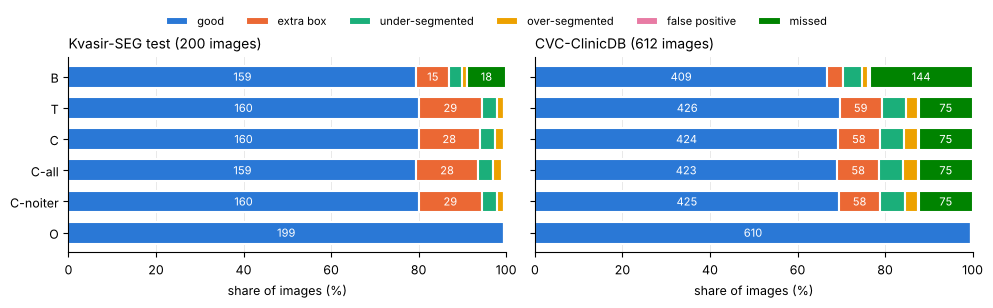

In [8]:
import matplotlib.pyplot as plt

LABELS = ["good", "extra_box", "under_segmentation", "over_segmentation", "false_positive", "missed"]
NAMES = ["good", "extra box", "under-segmented", "over-segmented", "false positive", "missed"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

fig, axes = plt.subplots(1, 2, figsize=(10, 2.9), sharey=True)
for ax, ds, title in zip(axes, ["kvasir_test", "clinicdb"], ["Kvasir-SEG test (200 images)", "CVC-ClinicDB (612 images)"]):
    t = err[err.dataset == ds].set_index("run")
    share = t[LABELS].div(t.images, axis=0) * 100
    left = pd.Series(0.0, index=share.index)
    for lab, name, col in zip(LABELS, NAMES, COLORS):
        ax.barh(share.index, share[lab], left=left, color=col, edgecolor="white", linewidth=1.5, label=name, height=0.7)
        for run, v in share[lab].items():
            if v >= 6:
                ax.text(left[run] + v / 2, run, str(int(t.loc[run, lab])), ha="center", va="center", fontsize=8, color="white")
        left += share[lab]
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlim(0, 100)
    ax.set_xlabel("share of images (%)")
    ax.grid(axis="x", color="#e5e5e5", linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.06), frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig("docs/figures/phase4_error_taxonomy.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. The ClinicDB images no pipeline segments

In [9]:
nf = pd.read_csv("docs/tables/phase4/errors_clinicdb_never_found.csv", index_col=0, dtype={"image_id": str})
c_clinic = pd.read_csv(f"{RUNS}/casp/clinicdb/per_image.csv", dtype={"image_id": str}).set_index("image_id")
found = c_clinic[~c_clinic.pred_empty]
print(f"{len(nf)} images get no mask from C: {nf.why.value_counts().to_dict()}")
print(f"oracle Dice on these images: {nf.oracle_dice.mean():.3f}")
print(f"median polyp area: missed {nf.gt_area_percent.median():.2f}% vs found {found.gt_area_percent.median():.2f}%")
print(f"highest detector confidence among them: {nf.max_confidence.max():.3f}")
nf.describe().round(3)

75 images get no mask from C: {'all candidates below t_low': 56, 'no candidate': 19}
oracle Dice on these images: 0.916
median polyp area: missed 5.26% vs found 7.00%
highest detector confidence among them: 0.248


,gt_area_percent,n_gt_polyps,n_candidates,max_confidence,oracle_dice
count,75.000,75.000,75.000,75.000,75.000
mean,8.713,1.107,1.347,0.111,0.916
std,8.653,0.421,1.121,0.083,0.064
min,0.337,1.000,0.000,0.000,0.586
25%,2.517,1.000,0.500,0.028,0.906
50%,5.262,1.000,1.000,0.102,0.933
75%,12.822,1.000,2.000,0.193,0.950
max,48.460,3.000,4.000,0.248,0.982


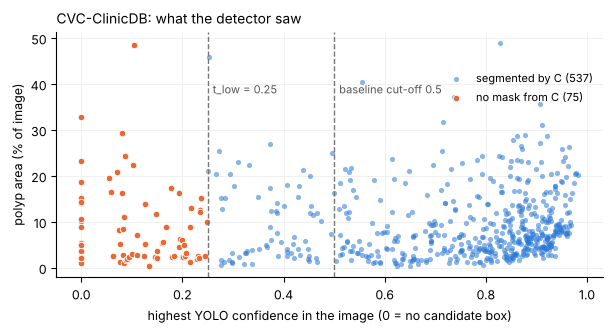

In [10]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.scatter(found.max_confidence, found.gt_area_percent, s=14, color="#2a78d6", alpha=0.55, label=f"segmented by C ({len(found)})", linewidths=0)
ax.scatter(nf.max_confidence, nf.gt_area_percent, s=22, color="#eb6834", label=f"no mask from C ({len(nf)})", edgecolors="white", linewidths=0.6)
for x, name in [(0.25, "t_low = 0.25"), (0.5, "baseline cut-off 0.5")]:
    ax.axvline(x, color="#777777", linewidth=1, linestyle="--")
    ax.text(x + 0.01, 38, name, fontsize=8, color="#555555")
ax.set_xlabel("highest YOLO confidence in the image (0 = no candidate box)")
ax.set_ylabel("polyp area (% of image)")
ax.set_title("CVC-ClinicDB: what the detector saw", loc="left", fontsize=10)
ax.grid(color="#eeeeee", linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.88))
plt.tight_layout()
plt.savefig("docs/figures/phase4_clinicdb_misses.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Where C beats B and where it loses (Kvasir-SEG test)

In [11]:
loses = pd.read_csv("docs/tables/phase4/errors_kvasir_c_loses.csv", index_col=0)
wins = pd.read_csv("docs/tables/phase4/errors_kvasir_c_wins.csv", index_col=0)
print(f"C better on {len(wins)} images; what B had there: {wins.label_b.value_counts().to_dict()}")
print(f"C worse on {len(loses)} images; what C has there: {loses.label_c.value_counts().to_dict()}")
loses

C better on 27 images; what B had there: {'missed': 17, 'good': 5, 'extra_box': 3, 'over_segmentation': 1, 'under_segmentation': 1}
C worse on 8 images; what C has there: {'extra_box': 5, 'good': 2, 'under_segmentation': 1}


,dice_b,dice_c,label_b,label_c,box_fp_b,box_fp_c,gt_area_percent,max_confidence,diff
image_id,,,,,,,,,
cju40taxlkrho0987smigg0x0,0.9712,0.6560,good,extra_box,0,1,10.185,0.7895,-0.3152
cju1ewnoh5z030855vpex9uzt,0.9708,0.6946,good,extra_box,0,1,10.187,0.7836,-0.2762
cju310f6val1v0855xo8tc3gu,0.9788,0.8216,extra_box,extra_box,1,2,57.643,0.5951,-0.1572
cju7f6cqy2ur20818t1saazbm,0.9179,0.8681,good,extra_box,0,1,12.713,0.8736,-0.0498
cju34c1xfyz920993itxkkfad,0.8849,0.8448,good,good,0,0,25.743,0.5026,-0.0401
cju6z1bzbwfq50817b2alatvr,0.7582,0.7416,good,good,0,0,42.494,0.5052,-0.0166
cju2oi8sq0i2y0801mektzvw8,0.9223,0.9204,extra_box,extra_box,1,4,76.337,0.5964,-0.0019
cju3tsh4lfsok0987w6x3a0v1,0.6516,0.6500,under_segmentation,under_segmentation,2,2,37.268,0.8956,-0.0016


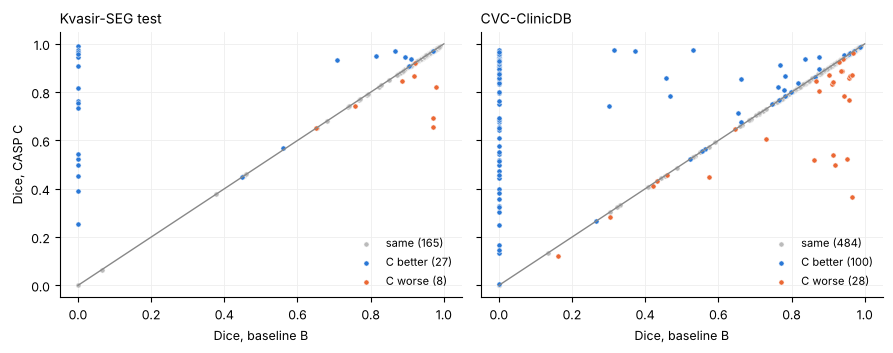

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
for ax, ds, title in zip(axes, ["kvasir_test", "clinicdb"], ["Kvasir-SEG test", "CVC-ClinicDB"]):
    b = pd.read_csv(f"{RUNS}/baseline/{ds}/per_image.csv", dtype={"image_id": str}).set_index("image_id")
    c = pd.read_csv(f"{RUNS}/casp/{ds}/per_image.csv", dtype={"image_id": str}).set_index("image_id")
    d = c.dice - b.dice
    for mask, col, name in [(d.abs() <= 1e-4, "#bbbbbb", "same"), (d > 1e-4, "#2a78d6", "C better"), (d < -1e-4, "#eb6834", "C worse")]:
        ax.scatter(b.dice[mask], c.dice[mask], s=14, color=col, label=f"{name} ({int(mask.sum())})", edgecolors="white", linewidths=0.4)
    ax.plot([0, 1], [0, 1], color="#888888", linewidth=1)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("Dice, baseline B")
    ax.grid(color="#eeeeee", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_ylabel("Dice, CASP C")
plt.tight_layout()
plt.savefig("docs/figures/phase4_c_vs_b.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
worst = pd.read_csv("docs/tables/phase4/errors_worst10.csv")
worst[(worst.run == "C") & (worst.dataset == "kvasir_test")]

,image_id,dice,label,gt_area_percent,pred_area_percent,n_gt_polyps,n_candidates,max_confidence,box_tp,box_fp,dataset,run
20,cju1dg44i4z3w0801nyz4p6zf,0.0000,missed,0.884,0.000,1,3,0.1407,0,0,kvasir_test,C
21,cju76o55nymqd0871h31sph9w,0.0657,extra_box,0.651,17.086,1,2,0.8275,1,1,kvasir_test,C
22,cju34uhepd3dd0799hs8782ad,0.2560,extra_box,2.482,16.880,1,2,0.3287,1,1,kvasir_test,C
23,cju2uzabhs6er0993x3aaf87p,0.3783,under_segmentation,10.119,8.090,1,2,0.8962,0,2,kvasir_test,C
24,cju5ktjwofed70817eg58ef7u,0.3894,extra_box,10.673,43.053,1,2,0.4513,1,1,kvasir_test,C
25,cju5ca9hcatkc0801jzwe7tfx,0.4474,under_segmentation,15.812,4.587,1,3,0.5976,0,1,kvasir_test,C
26,cju15ptjtppz40988odsm9azx,0.4520,over_segmentation,5.949,19.928,1,2,0.2945,0,1,kvasir_test,C
27,cju33belnbyhm0878yxl42233,0.4523,under_segmentation,6.691,1.955,2,3,0.8567,1,0,kvasir_test,C
28,cju33231uy4gi0993qc7b1jch,0.4533,over_segmentation,5.771,18.144,1,2,0.5748,0,1,kvasir_test,C
29,ck2bxiswtxuw80838qkisqjwz,0.4595,under_segmentation,44.239,13.454,1,1,0.8918,0,1,kvasir_test,C


## 6. Bias check

Subgroup analysis from `src/eval/bias_check.py`: each continuous factor is split into low / medium / high tertiles within each dataset, and C − B is a paired bootstrap interval inside each group. The ClinicDB example figure comes from `src/eval/clinicdb_examples.py`, which needs the ClinicDB images and the saved masks, so it is shown here as already generated.

In [14]:
r = subprocess.run([sys.executable, "src/eval/bias_check.py", "--runs", RUNS], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-3] if r.returncode == 0 else r.stderr[-2000:])

def bias(factor):
    t = pd.read_csv(f"docs/tables/phase4/bias_{factor}.csv")
    return t[t.dataset.isin(["kvasir_test", "clinicdb"])]

bias("dataset")[["dataset", "n", "dice_B", "dice_T", "dice_C", "miss_rate_B", "miss_rate_C", "c_minus_b", "ci_low", "ci_high"]].round(3)

corruption: 9 subgroup rows


,dataset,n,dice_B,dice_T,dice_C,miss_rate_B,miss_rate_C,c_minus_b,ci_low,ci_high
0,clinicdb,612,0.677,0.760,0.757,0.235,0.123,0.080,0.060,0.10
1,kvasir_test,200,0.831,0.893,0.891,0.090,0.005,0.061,0.032,0.09


In [15]:
order = {"low": 0, "medium": 1, "high": 2, "single": 0, "multiple": 1}
rows = []
for factor in ["polyp_size", "brightness", "contrast", "polyp_count"]:
    t = bias(factor).copy()
    t["k"] = t.subgroup.map(order)
    rows.append(t.sort_values(["dataset", "k"]))
sub = pd.concat(rows)
sub[["dataset", "factor", "subgroup", "n", "dice_B", "dice_C", "c_minus_b", "ci_low", "ci_high"]].round(3).set_index(["dataset", "factor", "subgroup"])

n  dice_B  dice_C  c_minus_b  ci_low  ci_high
dataset     factor      subgroup                                                 
clinicdb    polyp_size  low       204   0.614   0.714      0.100   0.064    0.138
                        medium    204   0.782   0.823      0.041   0.017    0.068
                        high      204   0.635   0.735      0.100   0.067    0.137
kvasir_test polyp_size  low        67   0.811   0.872      0.061   0.019    0.112
                        medium     66   0.863   0.899      0.037  -0.006    0.091
                        high       67   0.819   0.903      0.084   0.028    0.151
clinicdb    brightness  low       204   0.609   0.709      0.100   0.062    0.139
                        medium    204   0.635   0.738      0.103   0.069    0.138
                        high      204   0.787   0.825      0.038   0.015    0.064
kvasir_test brightness  low        67   0.820   0.909      0.090   0.028    0.157
                        medium     66   0.835   0.894      0.059   0.018    0.112
                        high       67   0.838   0.871      0.034  -0.006    0.081
clinicdb    contrast    low       204   0.614   0.693      0.079   0.046    0.116
                        medium    204   0.714   0.801      0.087   0.054    0.123
                        high      204   0.703   0.778      0.075   0.043    0.110
kvasir_test contrast    low        67   0.871   0.921      0.051   0.010    0.103
                        medium     66   0.858   0.882      0.023  -0.014    0.072
                        high       67   0.764   0.871      0.108   0.051    0.176
clinicdb    polyp_count single    582   0.689   0.770      0.081   0.062    0.102
                        multiple   30   0.452   0.513      0.061   0.012    0.119
kvasir_test polyp_count single    194   0.831   0.893      0.061   0.033    0.092
                        multiple    6   0.816   0.854      0.038   0.000    0.113

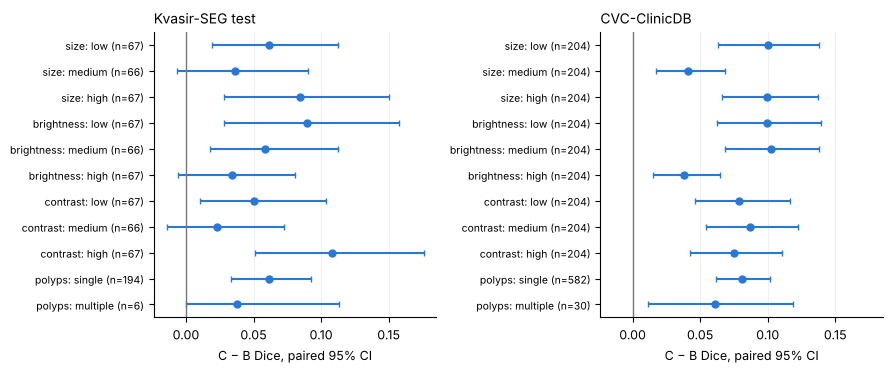

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True)
names = {"polyp_size": "size", "brightness": "brightness", "contrast": "contrast", "polyp_count": "polyps"}
for ax, ds, title in zip(axes, ["kvasir_test", "clinicdb"], ["Kvasir-SEG test", "CVC-ClinicDB"]):
    t = sub[sub.dataset == ds].reset_index(drop=True)
    y = range(len(t))[::-1]
    labels = [f"{names[f]}: {g} (n={n})" for f, g, n in zip(t.factor, t.subgroup, t.n)]
    ax.errorbar(t.c_minus_b, list(y), xerr=[t.c_minus_b - t.ci_low, t.ci_high - t.c_minus_b], fmt="o", color="#2a78d6",
                ecolor="#2a78d6", elinewidth=1.5, capsize=2, markersize=5)
    ax.axvline(0, color="#777777", linewidth=1)
    ax.set_yticks(list(y))
    ax.set_yticklabels(labels, fontsize=7.5)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("C − B Dice, paired 95% CI")
    ax.grid(axis="x", color="#eeeeee", linewidth=0.6)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("docs/figures/phase4_bias_summary.png", dpi=200, bbox_inches="tight")
plt.show()

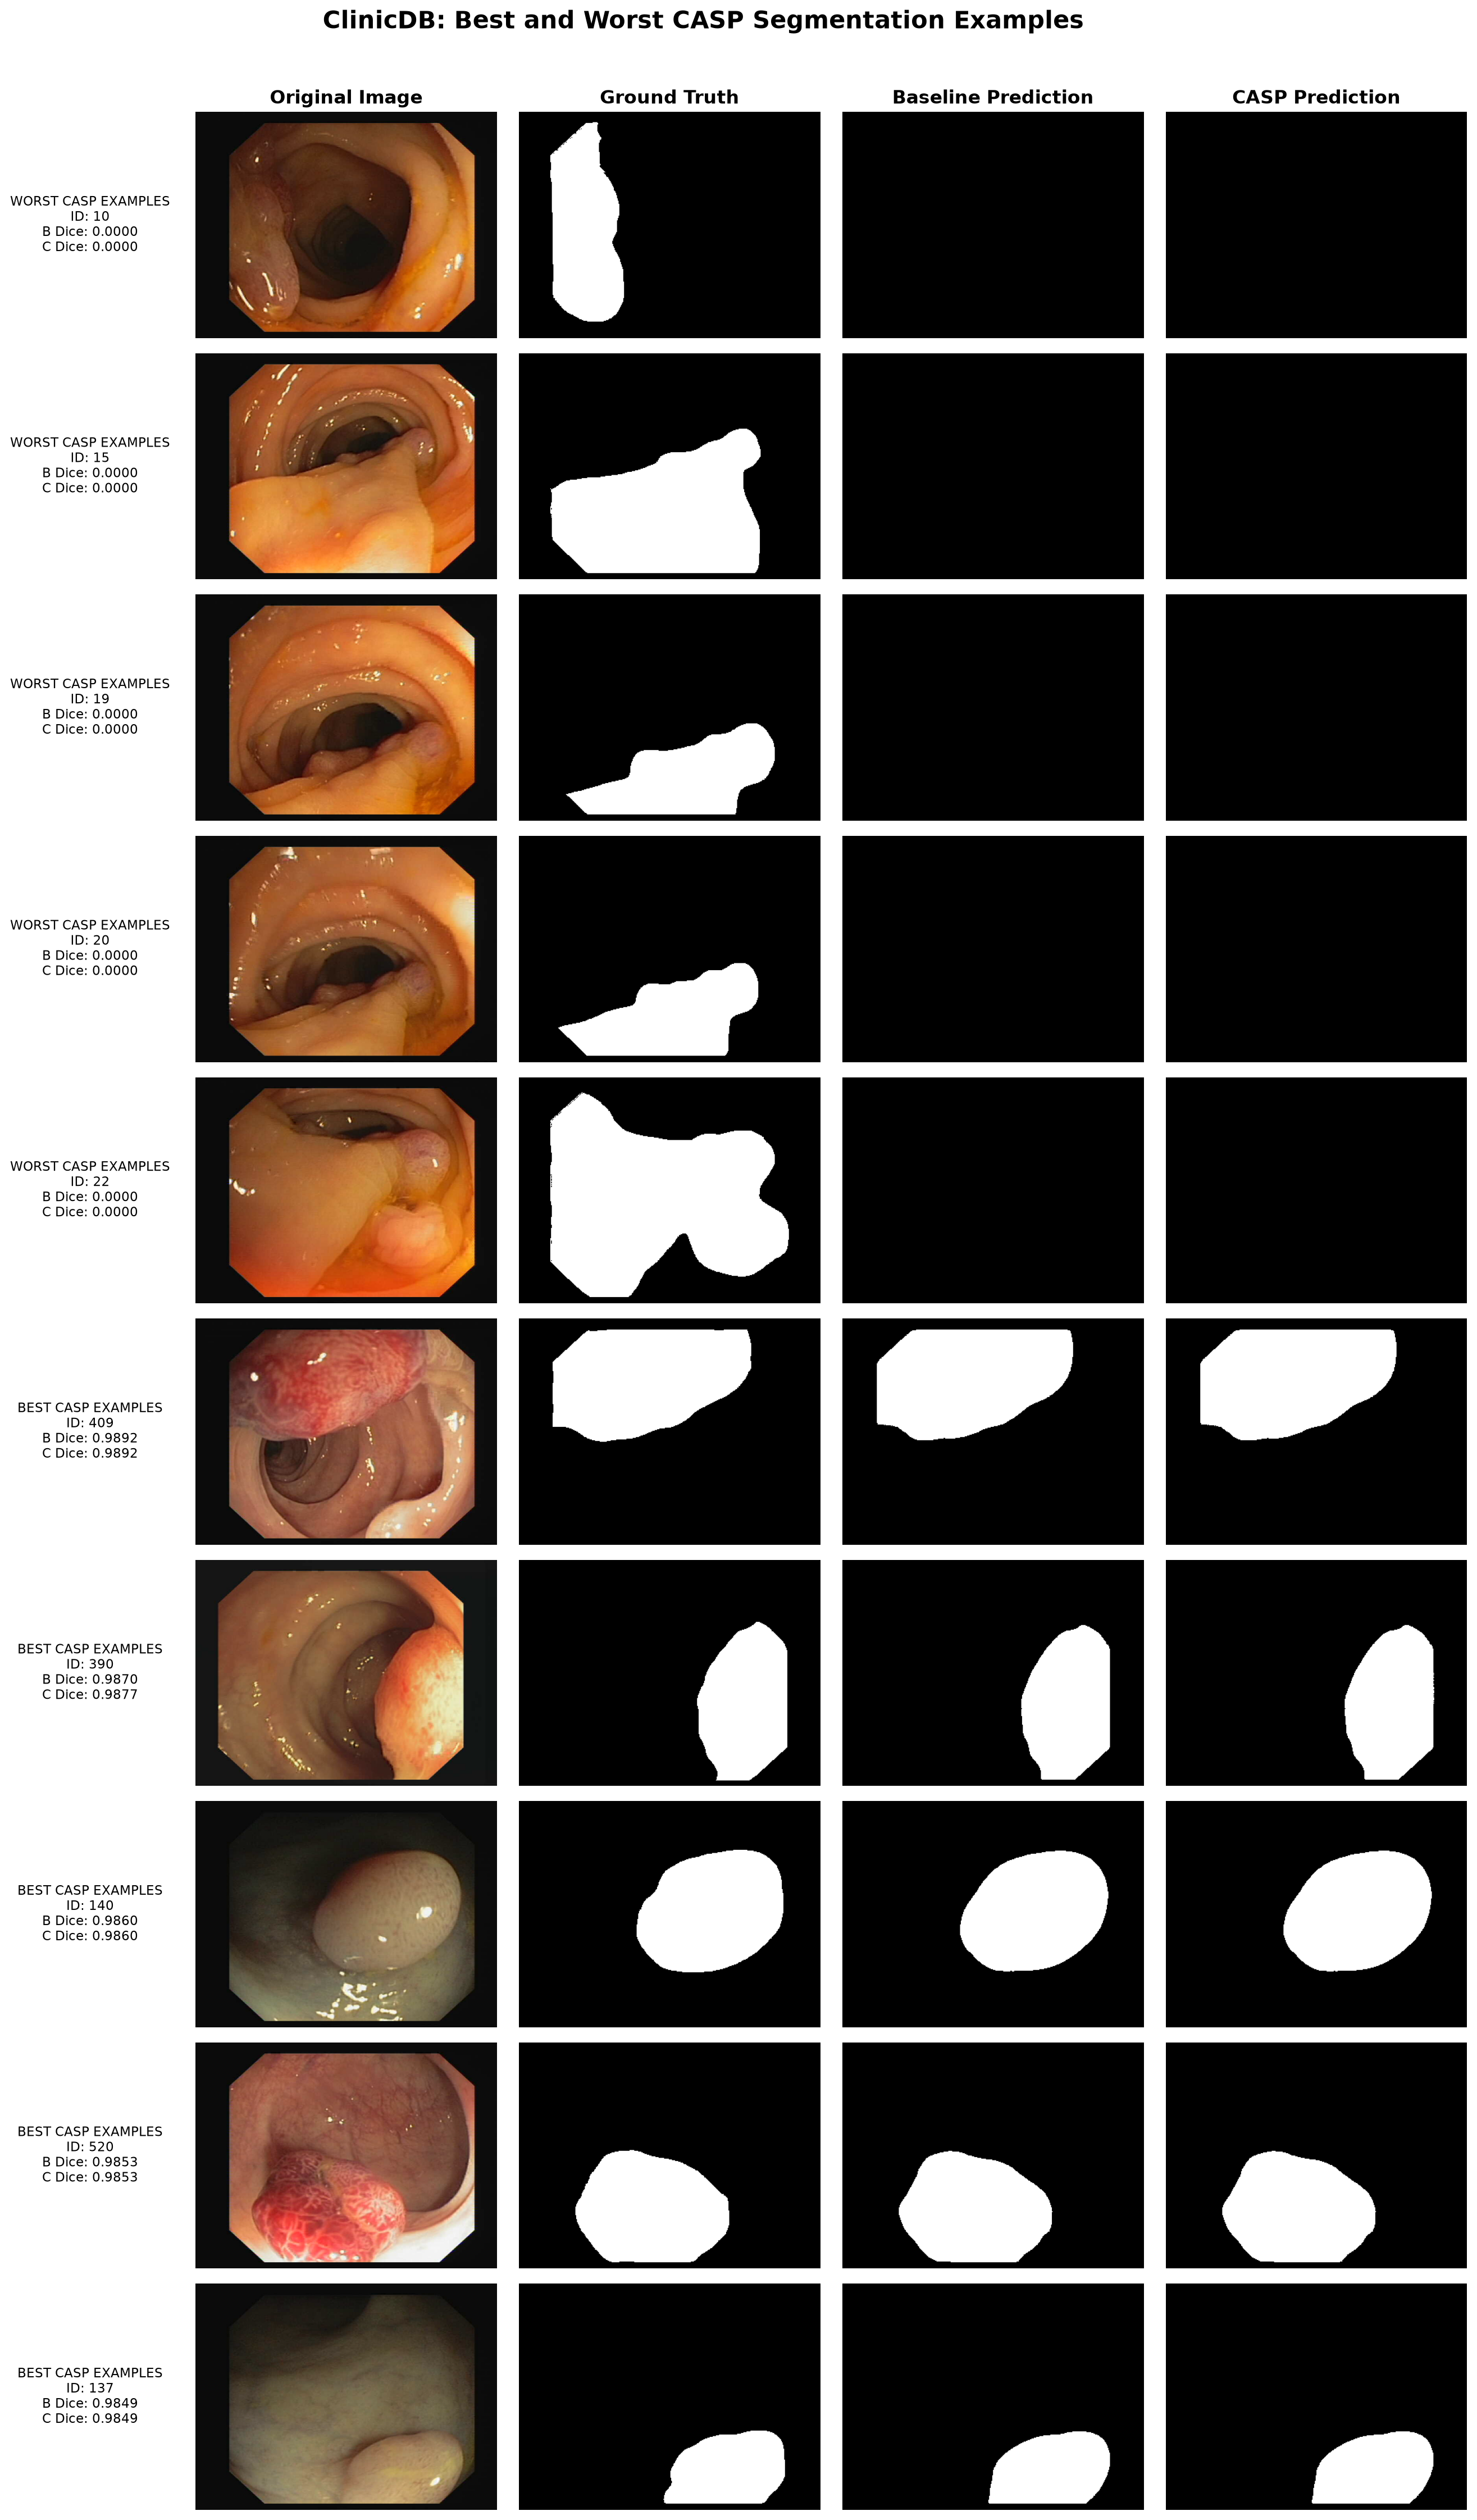

In [17]:
from IPython.display import Image as Img, display
display(Img(filename="docs/figures/phase4_examples_clinicdb.png", width=700))